# Airline Passenger Satisfaction — Exploratory Data Analysis

**Integrated Machine Learning Project — Subject 12 — Academic year 2026–2027**

Objective of this notebook: understand the structure and the quality of the data
before preprocessing. Section numbers follow the Phase 1 report.

All statistics are computed on the **training set only**, except for the
missing-value, duplicate and target checks, which also look at the test set.

## 0. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Paths are relative to the notebooks/ folder
TRAIN_PATH = "../Dataset/train.csv"
TEST_PATH = "../Dataset/test.csv"

## 3. Data loading and initial inspection

In [2]:
# Load the datasets
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [3]:
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

Training dataset: (103904, 25)
Testing dataset: (25976, 25)


In [4]:
# Display the first five rows of the training dataset
train_df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [5]:
# Display information about the dataset
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  str    
 3   Customer Type                      103904 non-null  str    
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  str    
 6   Class                              103904 non-null  str    
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      103904 non-null

## 4. Data quality assessment

### 4.1 Missing values

In [6]:
# Count missing values in each column
print("Missing values in training dataset:")
print(train_df.isnull().sum())

print("\nMissing values in testing dataset:")
print(test_df.isnull().sum())

# Percentage of missing arrival delays
train_missing_pct = train_df["Arrival Delay in Minutes"].isnull().mean() * 100
test_missing_pct = test_df["Arrival Delay in Minutes"].isnull().mean() * 100

print("\nMissing arrival delays (training): ", round(train_missing_pct, 2), "%")
print("Missing arrival delays (testing):  ", round(test_missing_pct, 2), "%")

Missing values in training dataset:
Unnamed: 0                             0
id                                     0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minu

### 4.2 Exact duplicates

In [7]:
# Check duplicate rows
print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())

Training duplicates: 0
Testing duplicates: 0


### 4.3 Duplicates without identifiers

In [8]:
# Columns used only as identifiers
id_columns = ["Unnamed: 0", "id"]

# Check duplicates without identifiers
train_duplicates = train_df.drop(
    columns=id_columns
).duplicated().sum()

test_duplicates = test_df.drop(
    columns=id_columns
).duplicated().sum()

print("Training duplicates without IDs:", train_duplicates)
print("Testing duplicates without IDs:", test_duplicates)

Training duplicates without IDs: 0
Testing duplicates without IDs: 0


## 5. Target variable distribution

In [9]:
# Count passengers in each satisfaction category
print("Training target distribution:")
print(train_df["satisfaction"].value_counts())

print("\nTesting target distribution:")
print(test_df["satisfaction"].value_counts())

# Same distribution in percentages
print("\nTraining target distribution (%):")
print((train_df["satisfaction"].value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((test_df["satisfaction"].value_counts(normalize=True) * 100).round(2))

Training target distribution:
satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64

Testing target distribution:
satisfaction
neutral or dissatisfied    14573
satisfied                  11403
Name: count, dtype: int64

Training target distribution (%):
satisfaction
neutral or dissatisfied    56.67
satisfied                  43.33
Name: proportion, dtype: float64

Testing target distribution (%):
satisfaction
neutral or dissatisfied    56.1
satisfied                  43.9
Name: proportion, dtype: float64


## 6. Numerical feature distributions

In [10]:
# Summary statistics of numerical features
train_df[
    ["Age", "Flight Distance",
     "Departure Delay in Minutes",
     "Arrival Delay in Minutes"]
].describe()

,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.000000,103904.000000,103904.000000,103594.000000
mean,39.379706,1189.448375,14.815618,15.178678
std,15.114964,997.147281,38.230901,38.698682
min,7.000000,31.000000,0.000000,0.000000
25%,27.000000,414.000000,0.000000,0.000000
50%,40.000000,843.000000,0.000000,0.000000
75%,51.000000,1743.000000,12.000000,13.000000
max,85.000000,4983.000000,1592.000000,1584.000000


**Figure 2** — Distributions of the four numerical variables.

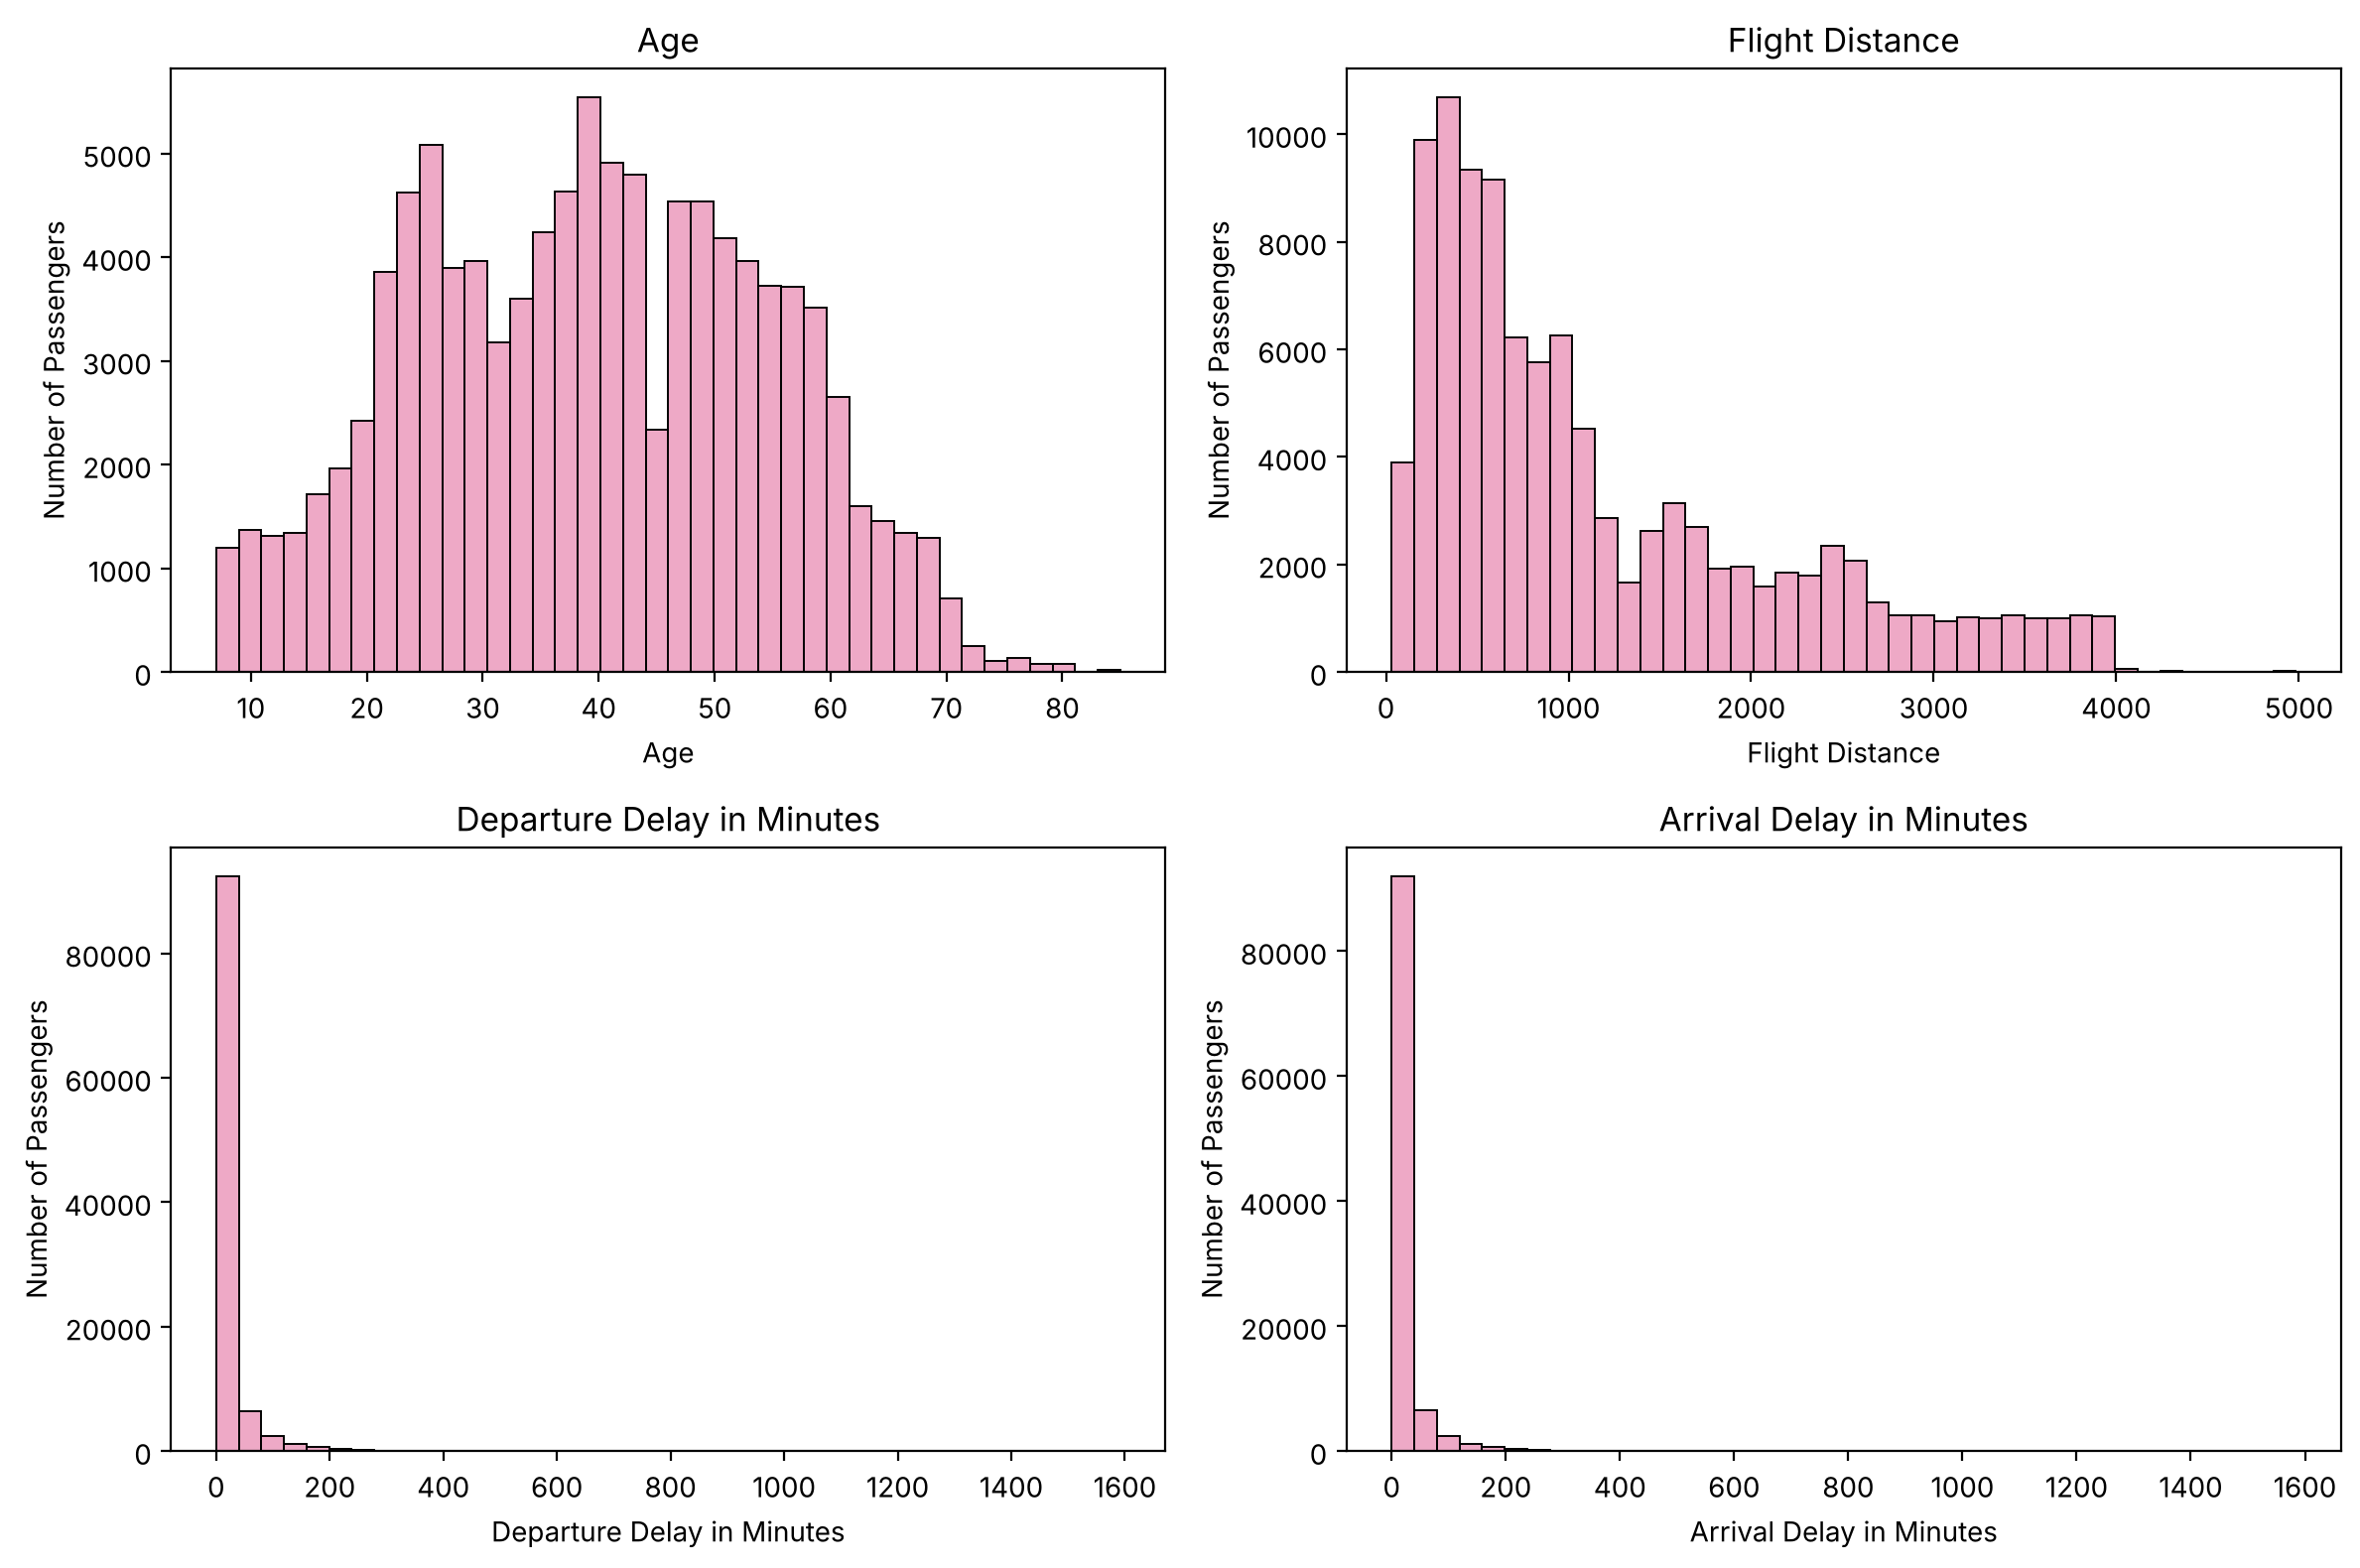

In [11]:
numerical_features = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, numerical_features):
    sns.histplot(
        data=train_df,
        x=feature,
        bins=40,
        color="#E98DB3",
        ax=ax
    )
    ax.set_title(feature)
    ax.set_ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

## 7. Categorical feature distributions

In [12]:
# Explore categorical features

categorical_features = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

for feature in categorical_features:
    print(f"\n--- {feature} ---")
    print(train_df[feature].value_counts())


--- Gender ---
Gender
Female    52727
Male      51177
Name: count, dtype: int64

--- Customer Type ---
Customer Type
Loyal Customer       84923
disloyal Customer    18981
Name: count, dtype: int64

--- Type of Travel ---
Type of Travel
Business travel    71655
Personal Travel    32249
Name: count, dtype: int64

--- Class ---
Class
Business    49665
Eco         46745
Eco Plus     7494
Name: count, dtype: int64


**Figure 3** — Category frequencies in the training set.

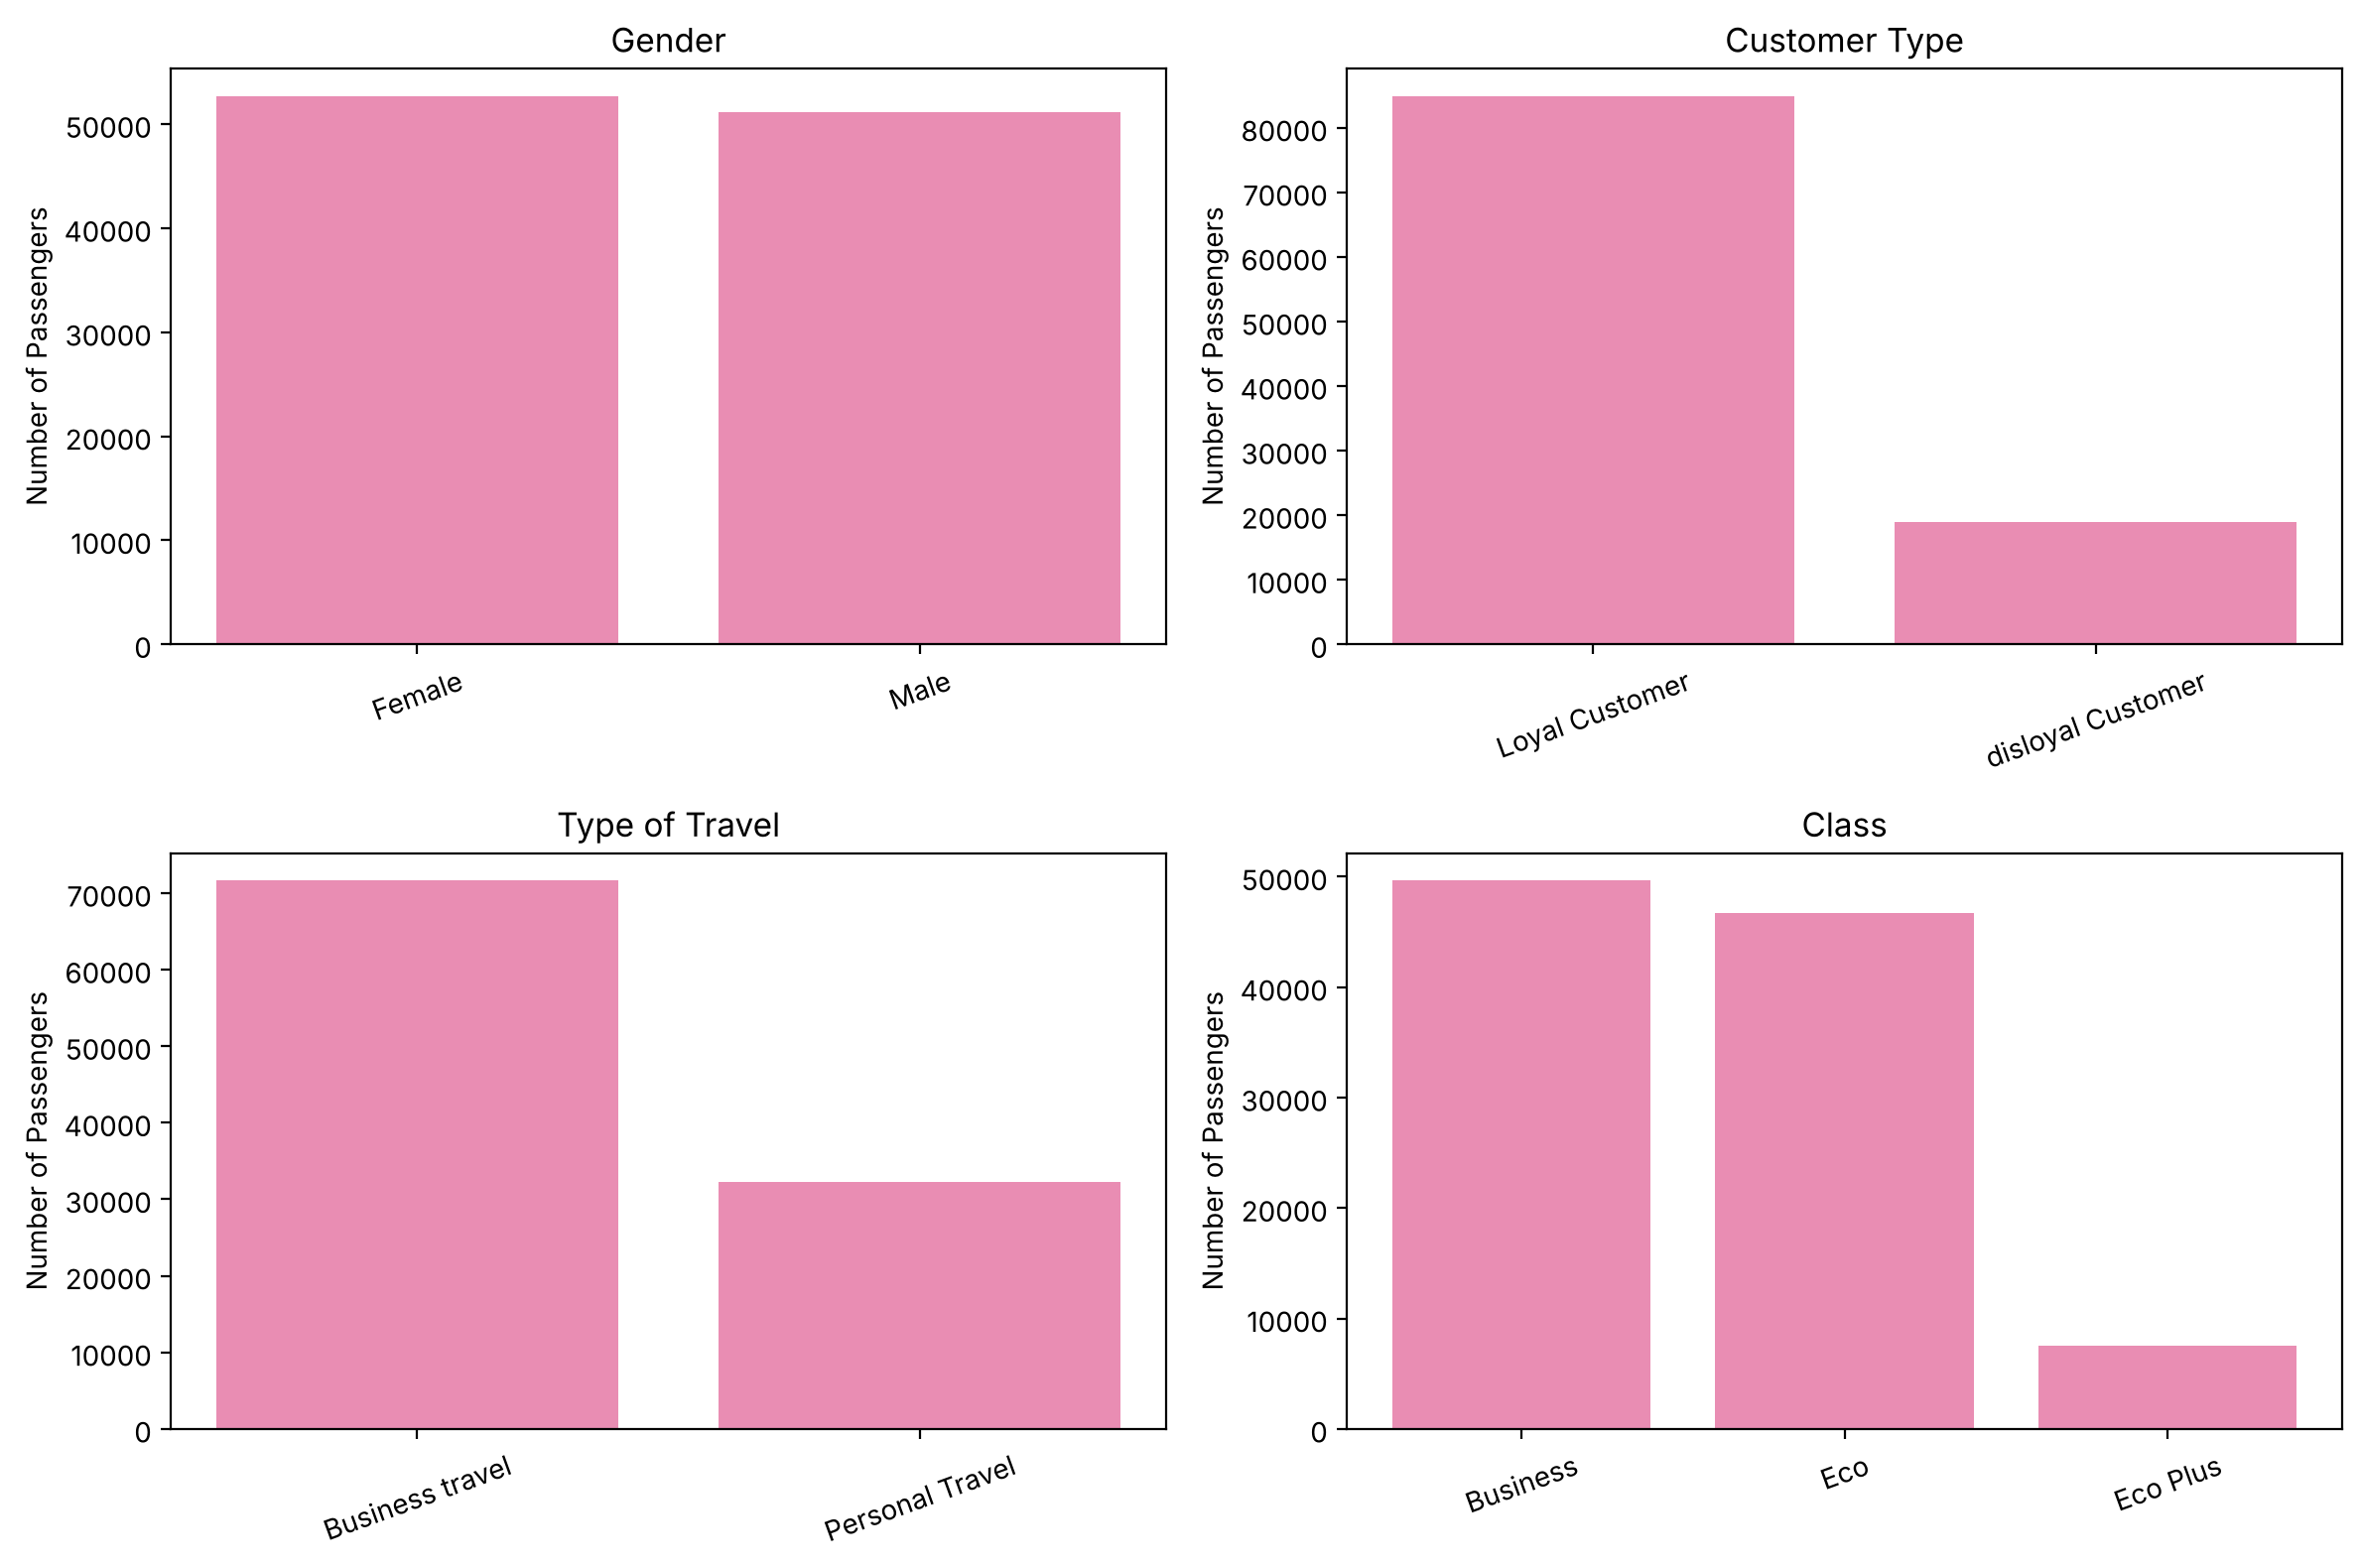

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, categorical_features):
    category_counts = train_df[feature].value_counts()

    ax.bar(
        category_counts.index,
        category_counts.values,
        color="#E98DB3"
    )

    ax.set_title(feature)
    ax.set_ylabel("Number of Passengers")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 8. Passenger characteristics and satisfaction

In [14]:
# Satisfaction percentage for each category

for feature in categorical_features:
    print(f"\n--- Satisfaction by {feature} ---")

    satisfaction_rate = pd.crosstab(
        train_df[feature],
        train_df["satisfaction"],
        normalize="index"
    ) * 100

    print(satisfaction_rate.round(2))


--- Satisfaction by Gender ---
satisfaction  neutral or dissatisfied  satisfied
Gender                                          
Female                          57.26      42.74
Male                            56.05      43.95

--- Satisfaction by Customer Type ---
satisfaction       neutral or dissatisfied  satisfied
Customer Type                                        
Loyal Customer                       52.27      47.73
disloyal Customer                    76.33      23.67

--- Satisfaction by Type of Travel ---
satisfaction     neutral or dissatisfied  satisfied
Type of Travel                                     
Business travel                    41.74      58.26
Personal Travel                    89.83      10.17

--- Satisfaction by Class ---
satisfaction  neutral or dissatisfied  satisfied
Class                                           
Business                        30.57      69.43
Eco                             81.39      18.61
Eco Plus                        75.39     

**Figure 4** — Satisfaction percentages within each passenger category.

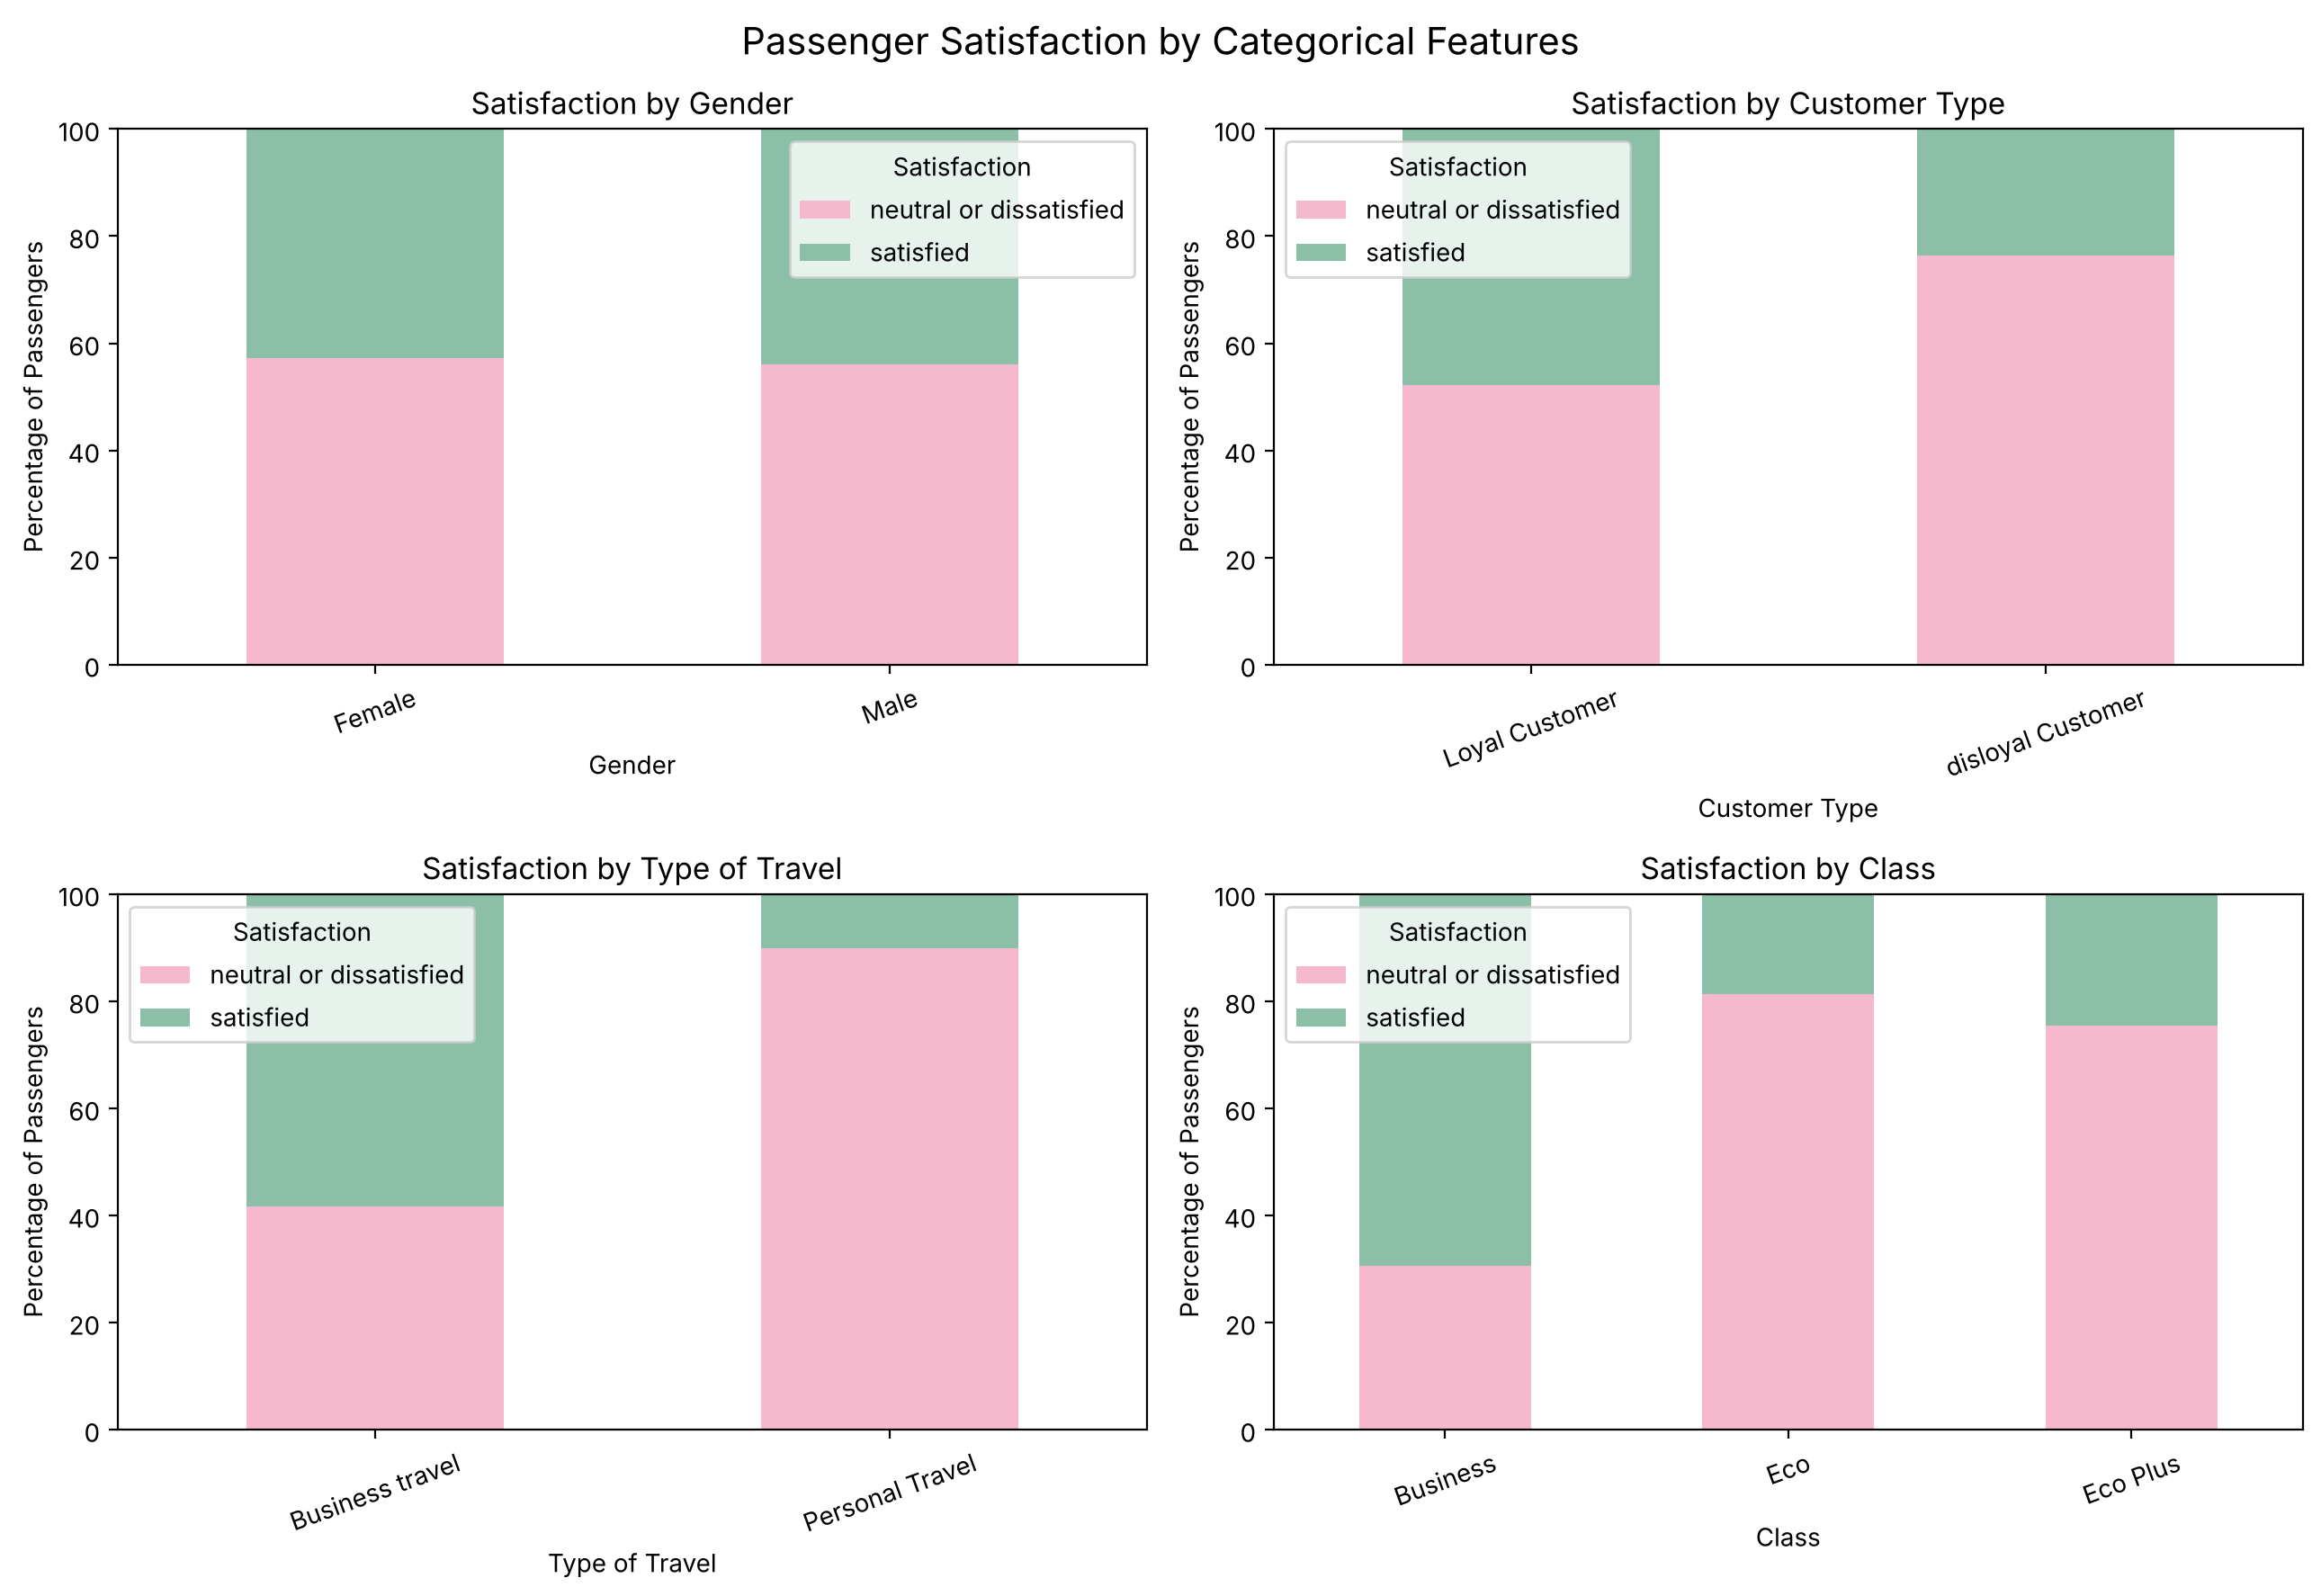

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, feature in zip(axes.flat, categorical_features):

    satisfaction_rates = pd.crosstab(
        train_df[feature],
        train_df["satisfaction"],
        normalize="index"
    ) * 100

    satisfaction_rates.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=["#F5B8CC", "#8CBFA7"]
    )

    ax.set_title(f"Satisfaction by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Percentage of Passengers")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Satisfaction")

plt.suptitle(
    "Passenger Satisfaction by Categorical Features",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 9. Overall airline service ratings

In [16]:
# Average rating of the 14 airline services

service_features = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness"
]

# Calculate the average rating for each service
average_ratings = train_df[service_features].mean()

# Sort from highest to lowest
average_ratings = average_ratings.sort_values(
    ascending=False
)

print(average_ratings.round(2))

Inflight service                     3.64
Baggage handling                     3.63
Seat comfort                         3.44
On-board service                     3.38
Inflight entertainment               3.36
Leg room service                     3.35
Checkin service                      3.30
Cleanliness                          3.29
Online boarding                      3.25
Food and drink                       3.20
Departure/Arrival time convenient    3.06
Gate location                        2.98
Ease of Online booking               2.76
Inflight wifi service                2.73
dtype: float64


**Figure 5** — Raw mean service rating (zero values included).

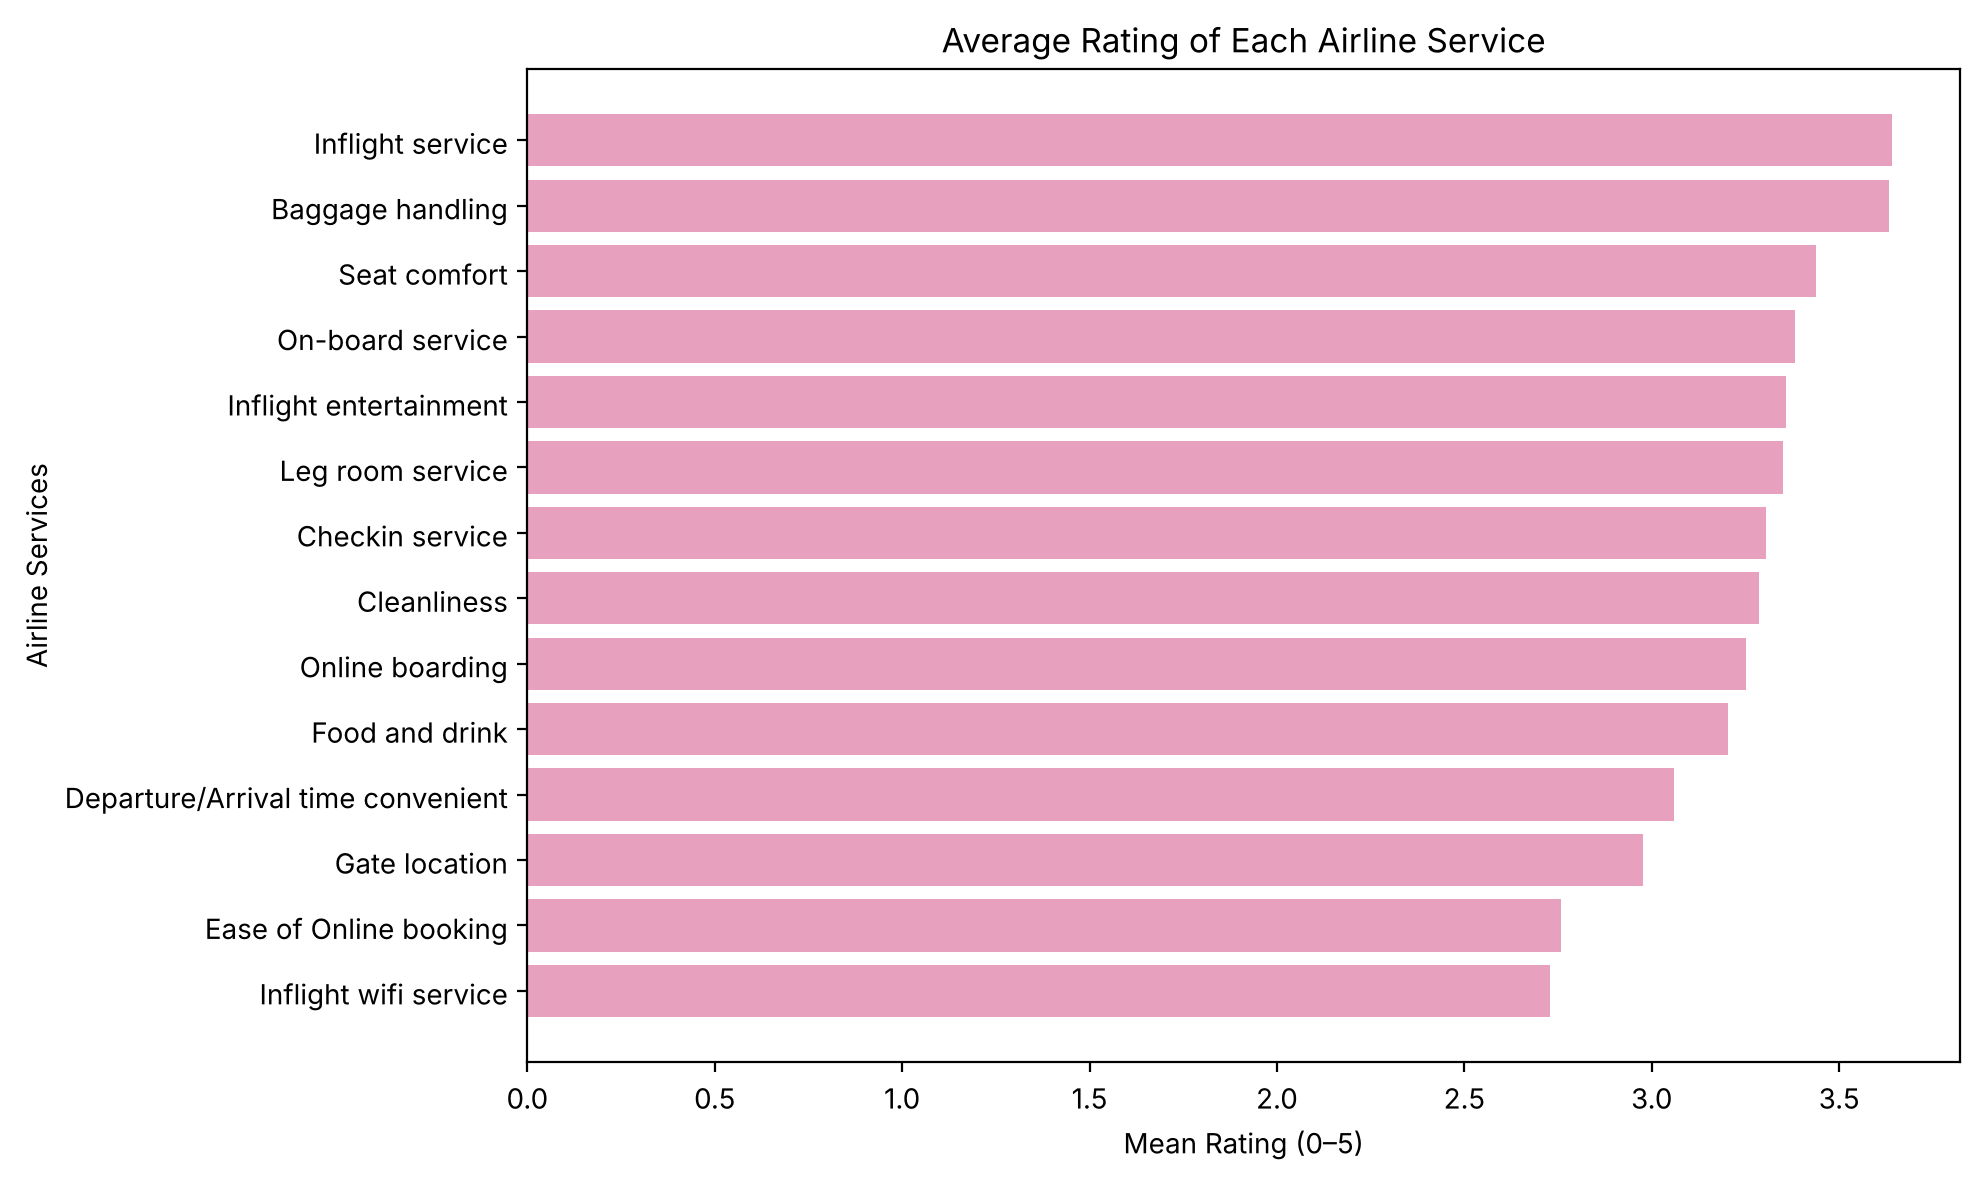

In [17]:
plt.figure(figsize=(10, 6))

plt.barh(
    average_ratings.index,
    average_ratings.values,
    color="#E8A0BF"
)

plt.title("Average Rating of Each Airline Service")
plt.xlabel("Mean Rating (0–5)")
plt.ylabel("Airline Services")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Service ratings by satisfaction

In [18]:
# Compare average service ratings by satisfaction

service_by_satisfaction = train_df.groupby(
    "satisfaction"
)[service_features].mean()

# Display the results
print(service_by_satisfaction.T.round(2))

satisfaction                       neutral or dissatisfied  satisfied
Inflight wifi service                                 2.40       3.16
Departure/Arrival time convenient                     3.13       2.97
Ease of Online booking                                2.55       3.03
Gate location                                         2.98       2.98
Food and drink                                        2.96       3.52
Online boarding                                       2.66       4.03
Seat comfort                                          3.04       3.97
Inflight entertainment                                2.89       3.96
On-board service                                      3.02       3.86
Leg room service                                      2.99       3.82
Baggage handling                                      3.38       3.97
Checkin service                                       3.04       3.65
Inflight service                                      3.39       3.97
Cleanliness         

## 11. Ranking the differences between satisfaction groups

In [19]:
# Calculate the difference between satisfaction groups

service_comparison = service_by_satisfaction.T.copy()

service_comparison["Difference"] = (
    service_comparison["satisfied"]
    - service_comparison["neutral or dissatisfied"]
)

# Sort by difference, highest first
service_comparison = service_comparison.sort_values(
    by="Difference",
    ascending=False
)

# Display results
print(service_comparison.round(2))

satisfaction                       neutral or dissatisfied  satisfied  \
Online boarding                                       2.66       4.03   
Inflight entertainment                                2.89       3.96   
Seat comfort                                          3.04       3.97   
On-board service                                      3.02       3.86   
Leg room service                                      2.99       3.82   
Cleanliness                                           2.94       3.74   
Inflight wifi service                                 2.40       3.16   
Checkin service                                       3.04       3.65   
Baggage handling                                      3.38       3.97   
Inflight service                                      3.39       3.97   
Food and drink                                        2.96       3.52   
Ease of Online booking                                2.55       3.03   
Gate location                                      

**Figure 6** — Ranking of the service-rating differences between satisfaction groups.

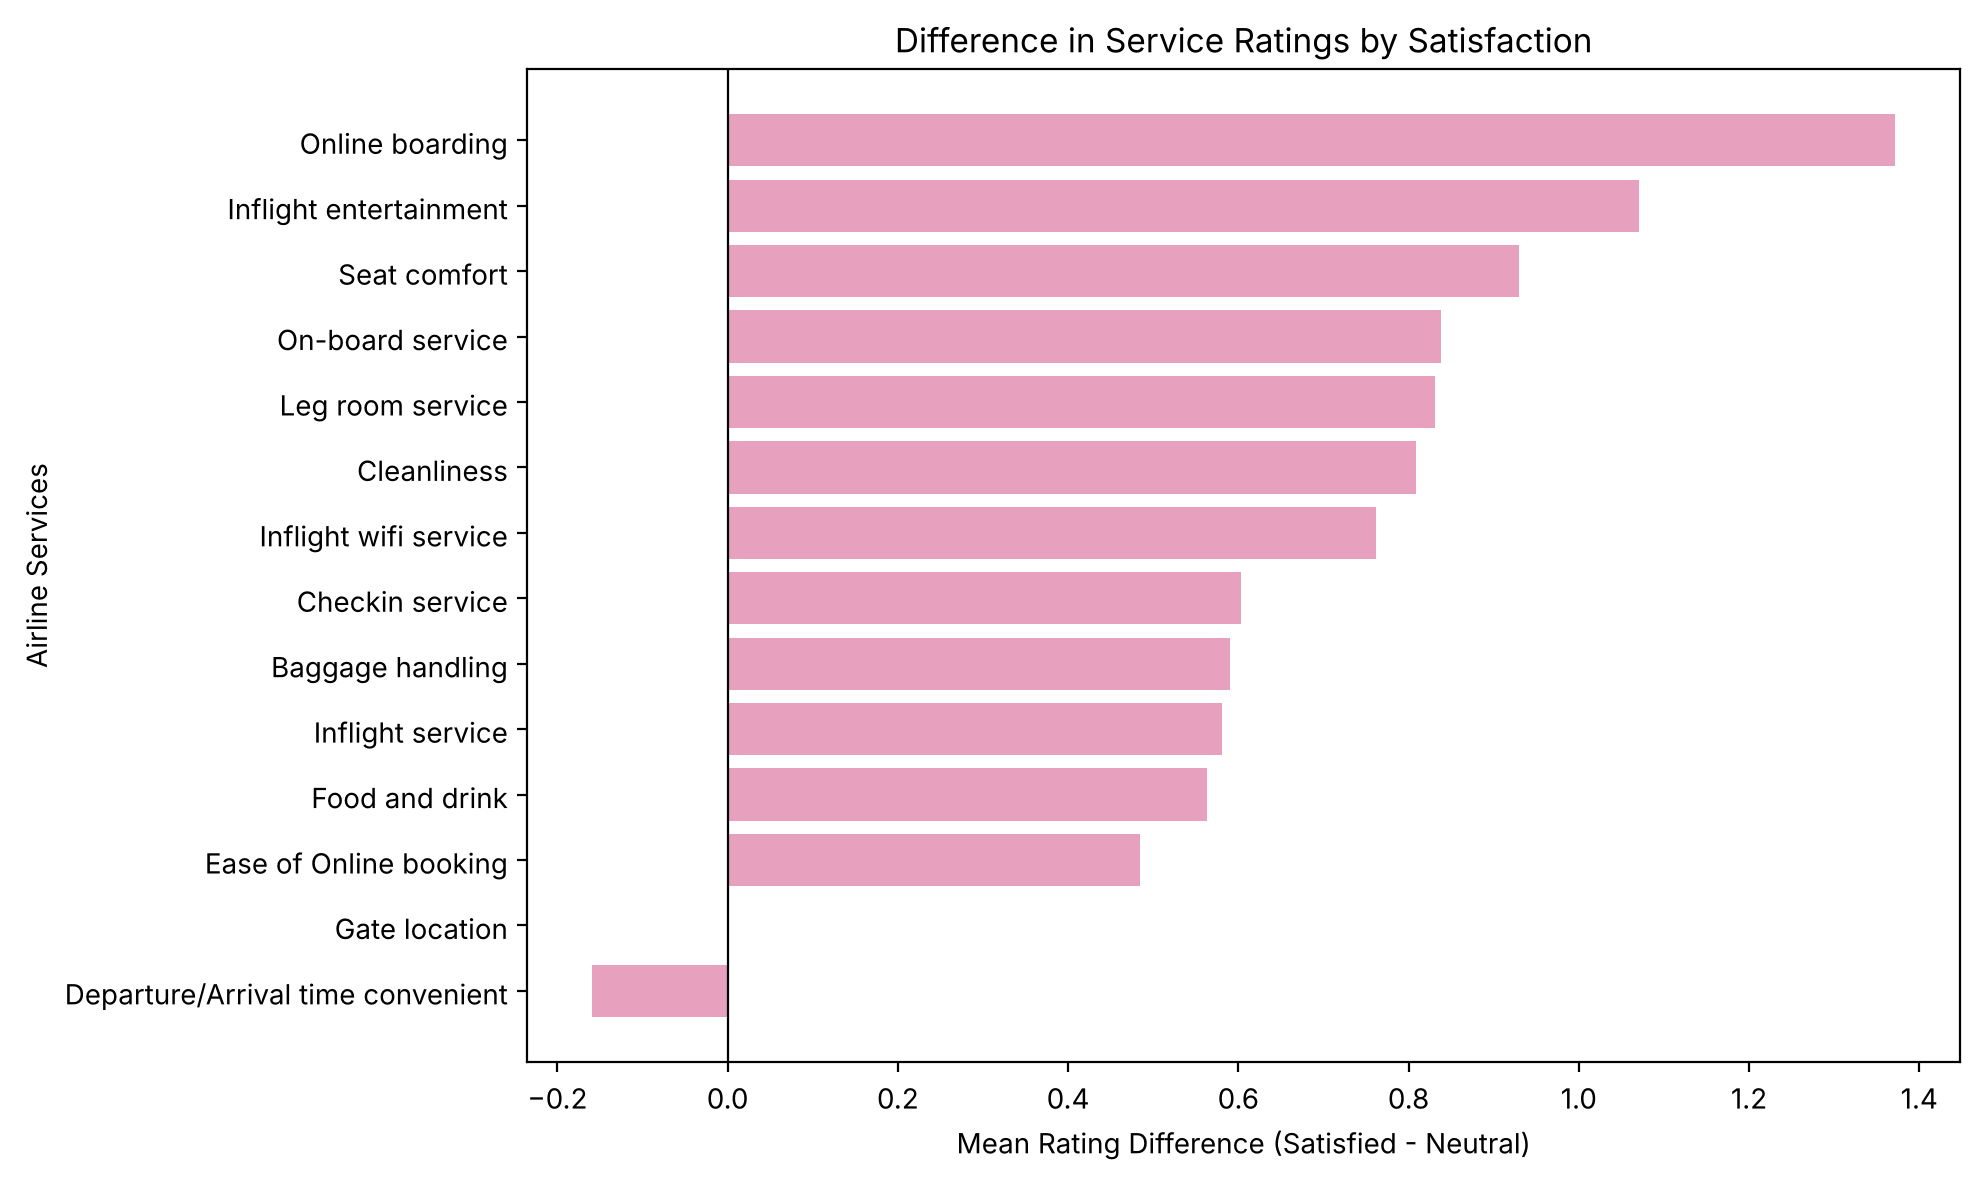

In [20]:
plt.figure(figsize=(10, 6))

plt.barh(
    service_comparison.index,
    service_comparison["Difference"],
    color="#E8A0BF"
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Difference in Service Ratings by Satisfaction")
plt.xlabel("Mean Rating Difference (Satisfied - Neutral)")
plt.ylabel("Airline Services")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 12. Investigation of zero service ratings

According to the dataset description, a rating of 0 means *Not Applicable*,
not a bad evaluation.

In [21]:
# Count zero ratings for each service

zero_counts = (train_df[service_features] == 0).sum()

zero_percentages = (
    zero_counts / len(train_df) * 100
)

zero_analysis = pd.DataFrame({
    "Zero Count": zero_counts,
    "Zero Percentage": zero_percentages
})

zero_analysis = zero_analysis.sort_values(
    by="Zero Count",
    ascending=False
)

print(zero_analysis.round(2))

                                   Zero Count  Zero Percentage
Departure/Arrival time convenient        5300             5.10
Ease of Online booking                   4487             4.32
Inflight wifi service                    3103             2.99
Online boarding                          2428             2.34
Leg room service                          472             0.45
Food and drink                            107             0.10
Inflight entertainment                     14             0.01
Cleanliness                                12             0.01
Inflight service                            3             0.00
On-board service                            3             0.00
Gate location                               1             0.00
Seat comfort                                1             0.00
Checkin service                             1             0.00
Baggage handling                            0             0.00


**Figure 7** — Percentage of zero ratings for each service.

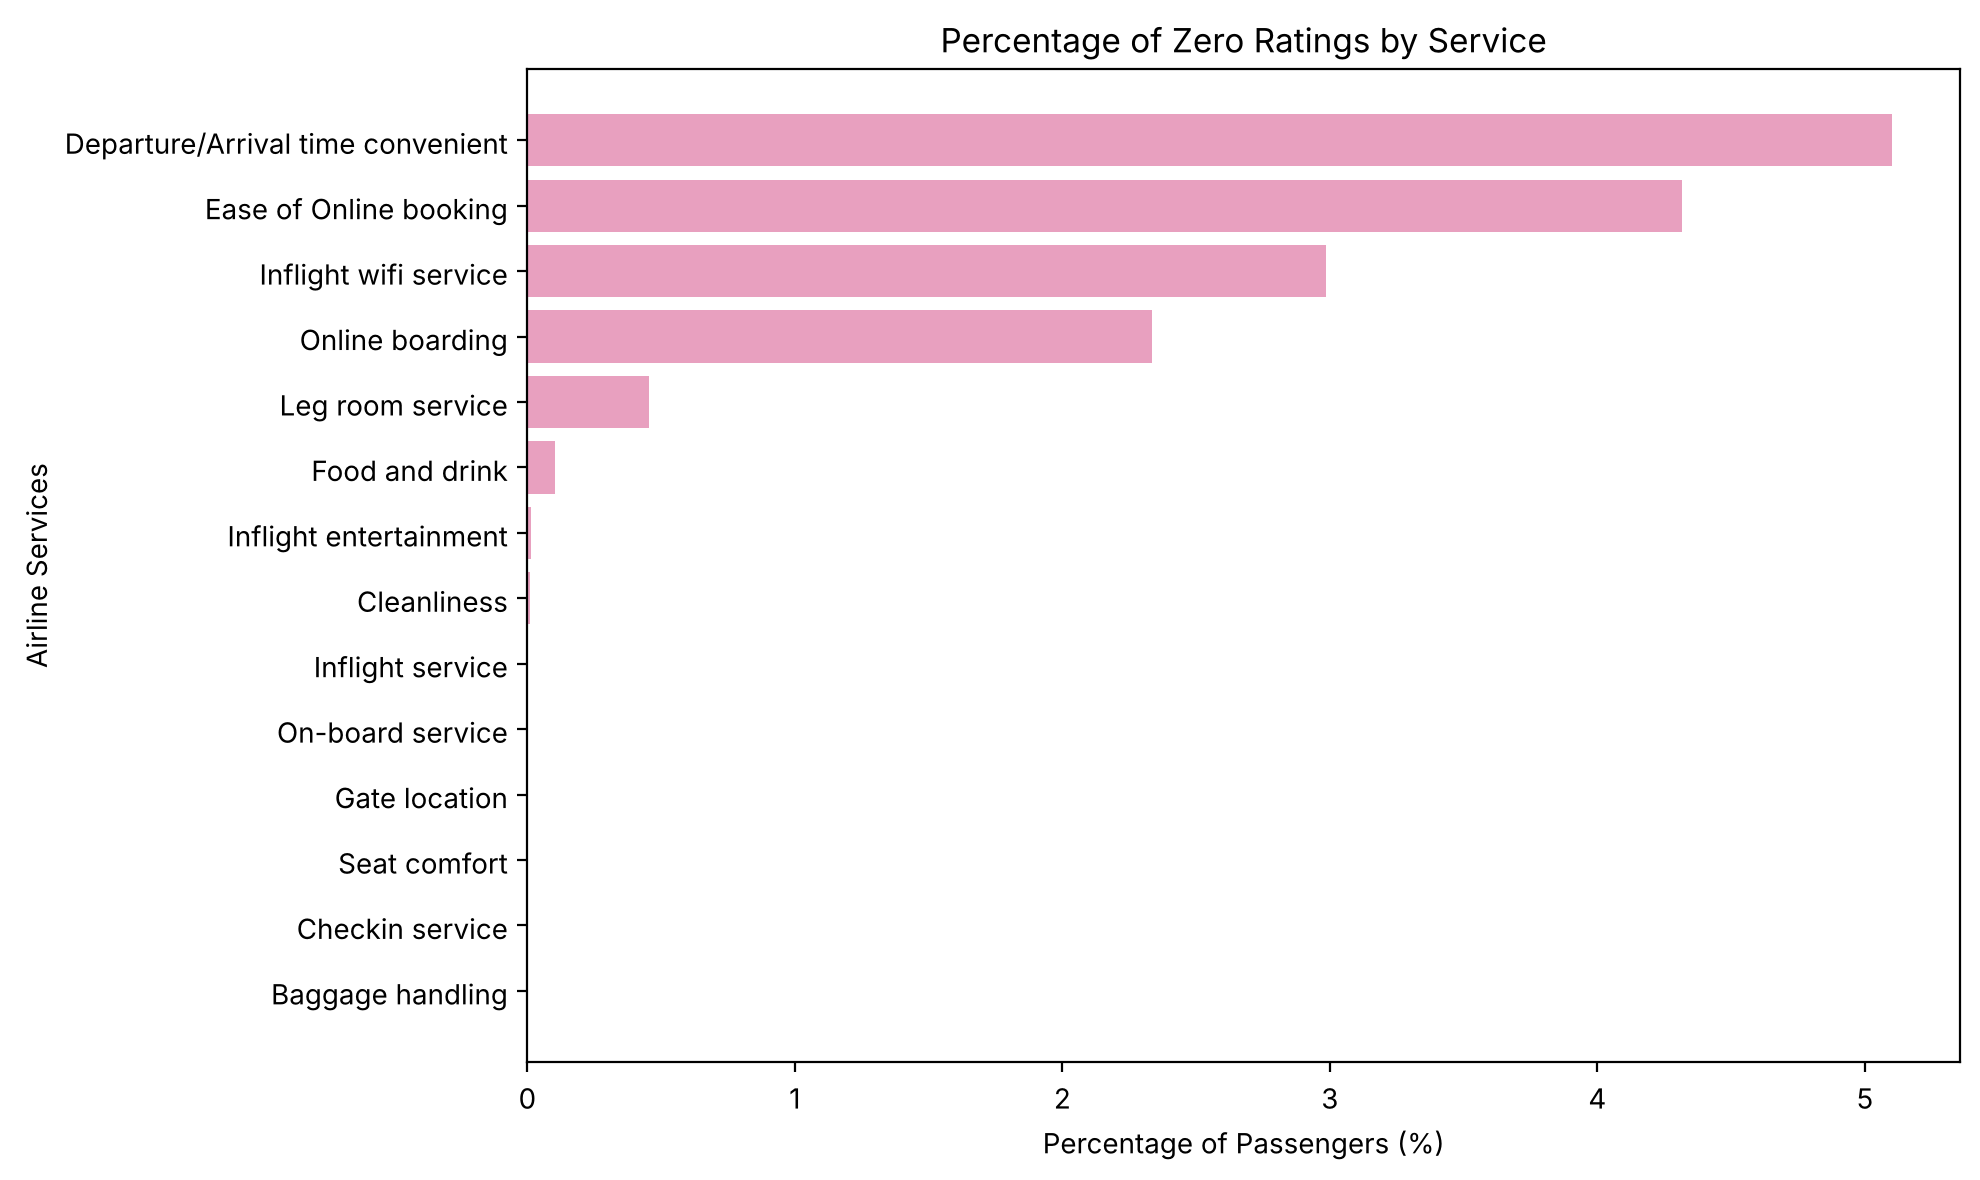

In [22]:
plt.figure(figsize=(10, 6))

plt.barh(
    zero_analysis.index,
    zero_analysis["Zero Percentage"],
    color="#E8A0BF"
)

plt.title("Percentage of Zero Ratings by Service")
plt.xlabel("Percentage of Passengers (%)")
plt.ylabel("Airline Services")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 13. Impact of excluding zeros from the averages

In [23]:
# Compare average ratings with and without zeros

raw_averages = train_df[service_features].mean()

nonzero_averages = (
    train_df[service_features]
    .replace(0, float("nan"))
    .mean()
)

average_comparison = pd.DataFrame({
    "Raw Average": raw_averages,
    "Average Without Zeros": nonzero_averages
})

average_comparison["Difference"] = (
    average_comparison["Average Without Zeros"]
    - average_comparison["Raw Average"]
)

print(
    average_comparison
    .sort_values("Difference", ascending=False)
    .round(2)
)

                                   Raw Average  Average Without Zeros  \
Departure/Arrival time convenient         3.06                   3.22   
Ease of Online booking                    2.76                   2.88   
Inflight wifi service                     2.73                   2.81   
Online boarding                           3.25                   3.33   
Leg room service                          3.35                   3.37   
Food and drink                            3.20                   3.21   
Inflight entertainment                    3.36                   3.36   
Cleanliness                               3.29                   3.29   
Inflight service                          3.64                   3.64   
On-board service                          3.38                   3.38   
Seat comfort                              3.44                   3.44   
Checkin service                           3.30                   3.30   
Gate location                             2.98     

**Figure 8** — Change in the average rating when zeros are excluded.

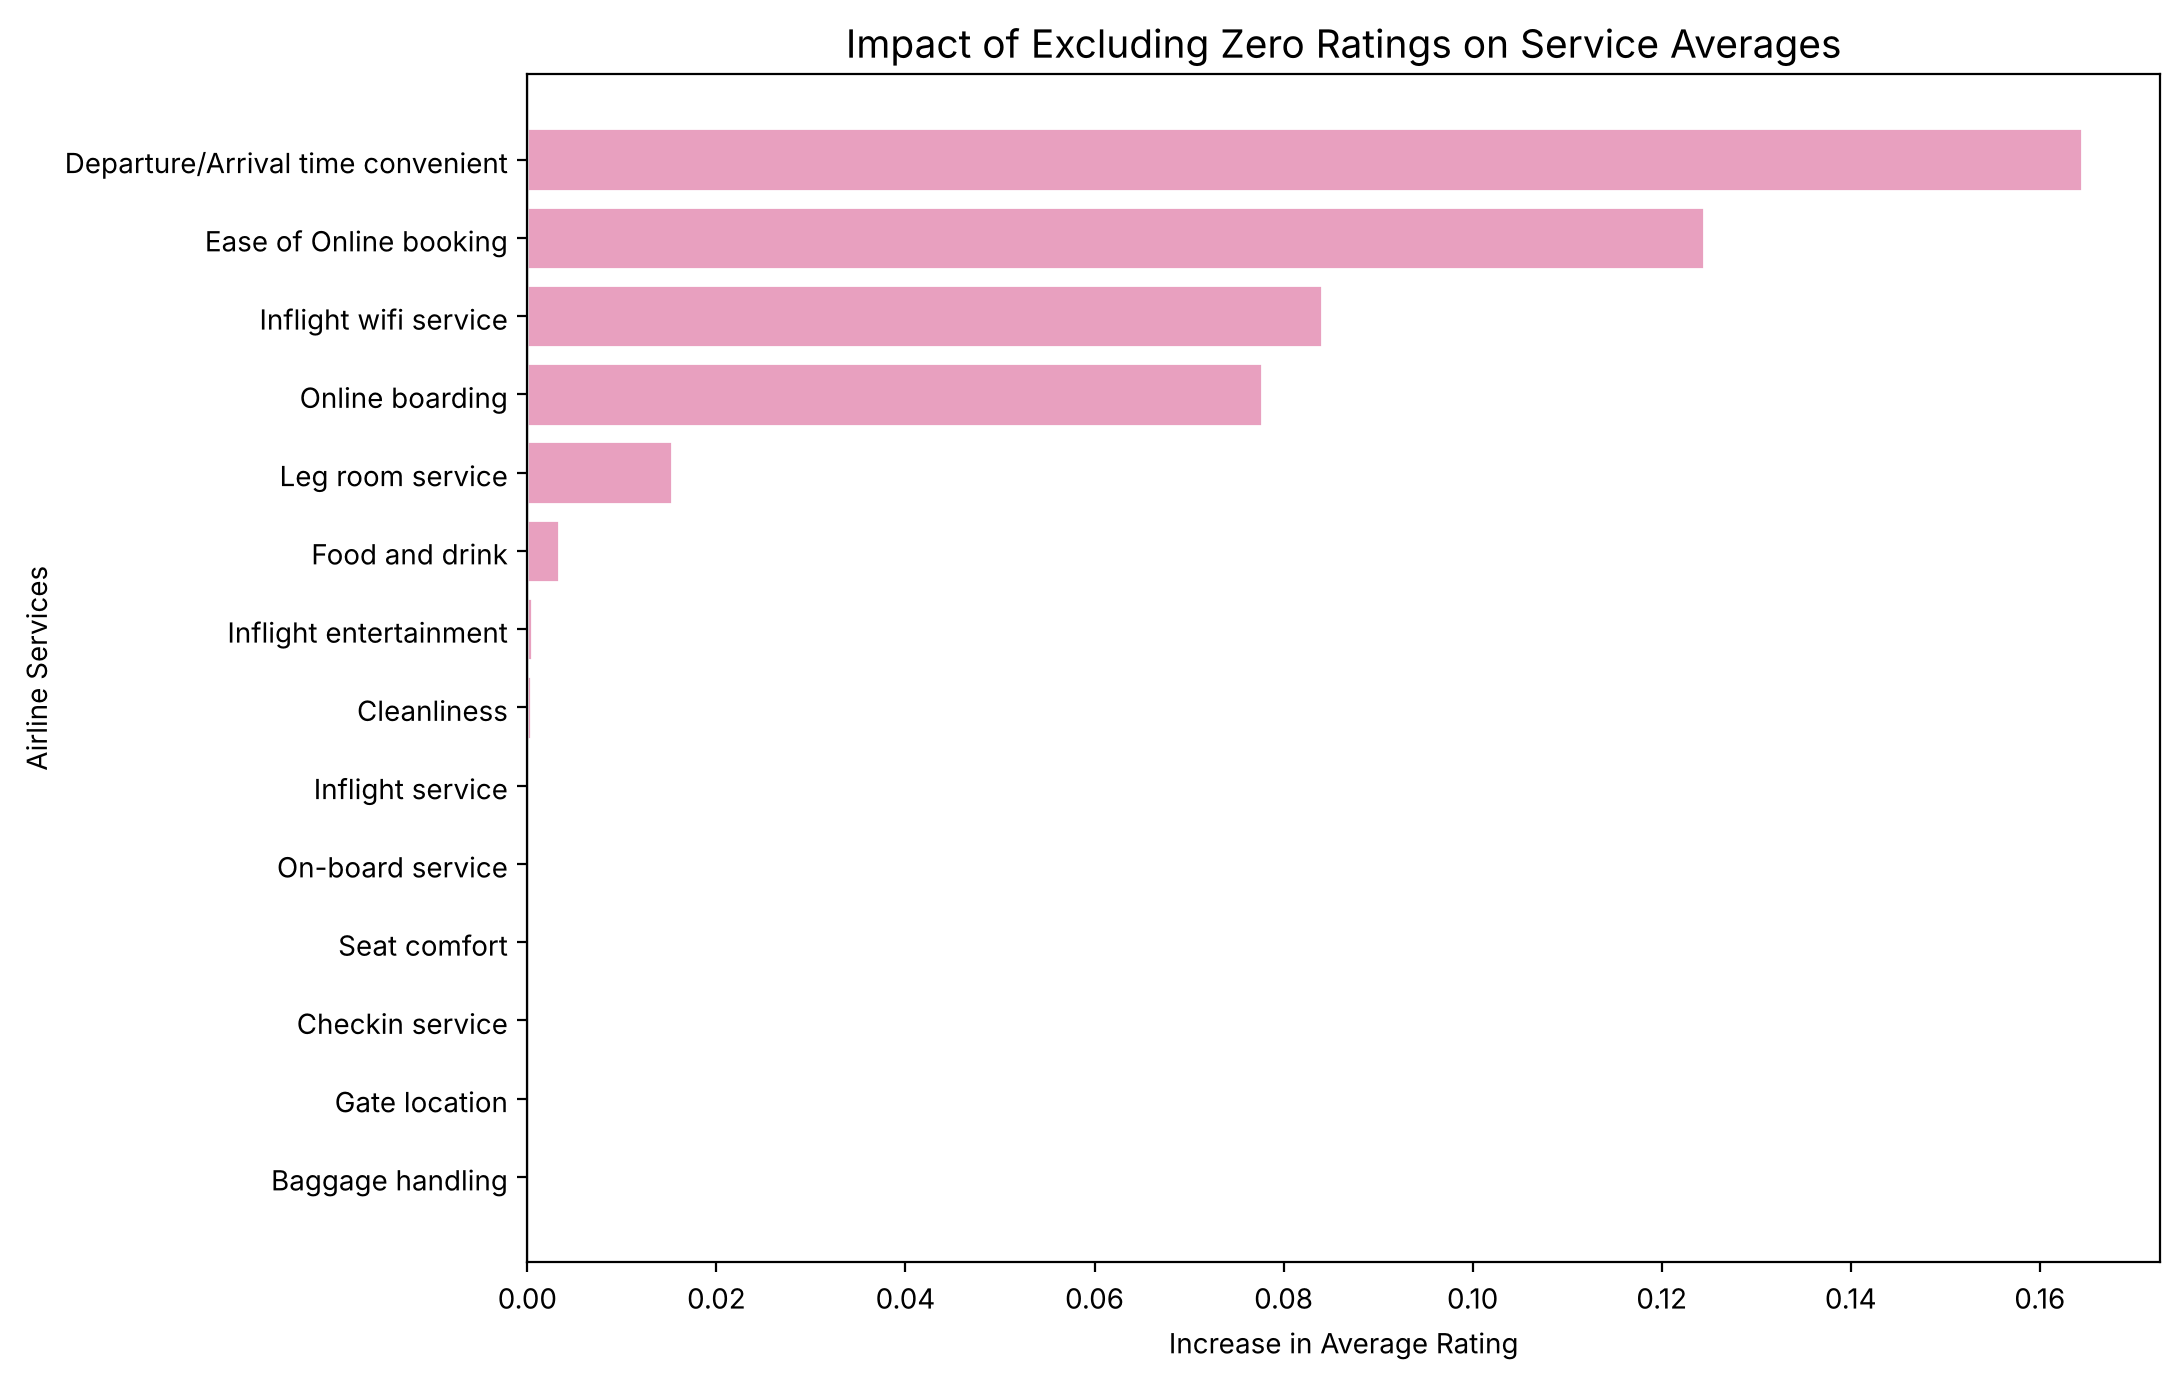

In [24]:
# Sort services by the impact of excluding zeros
plot_data = average_comparison.sort_values(
    by="Difference",
    ascending=True
)

plt.figure(figsize=(11, 7))

# Create horizontal bar chart
plt.barh(
    plot_data.index,
    plot_data["Difference"],
    color="#E8A0BF",
    edgecolor="white"
)

plt.title(
    "Impact of Excluding Zero Ratings on Service Averages",
    fontsize=14
)

plt.xlabel("Increase in Average Rating")
plt.ylabel("Airline Services")

plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

## 14. Zero ratings and satisfaction

Section 13 showed that zeros change the averages. The question for preprocessing is
different: **is a zero rating related to the target?**

For each service containing enough zeros, we compare the satisfaction rate of
passengers who gave 0 with the satisfaction rate of the other passengers.

In [25]:
# 1 if the passenger is satisfied, 0 otherwise
is_satisfied = train_df["satisfaction"] == "satisfied"

zero_rows = []

for service in service_features:
    has_zero = train_df[service] == 0

    # Ignore services with almost no zeros (rates would not be reliable)
    if has_zero.sum() < 100:
        continue

    zero_rows.append({
        "Service": service,
        "Zero Count": has_zero.sum(),
        "Satisfied if 0 (%)": is_satisfied[has_zero].mean() * 100,
        "Satisfied if not 0 (%)": is_satisfied[~has_zero].mean() * 100,
    })

zero_satisfaction = pd.DataFrame(zero_rows).set_index("Service")

print(zero_satisfaction.round(2))

                                   Zero Count  Satisfied if 0 (%)  \
Service                                                             
Inflight wifi service                    3103               99.74   
Departure/Arrival time convenient        5300               47.55   
Ease of Online booking                   4487               66.41   
Food and drink                            107               46.73   
Online boarding                          2428               55.64   
Leg room service                          472               35.17   

                                   Satisfied if not 0 (%)  
Service                                                    
Inflight wifi service                               41.60  
Departure/Arrival time convenient                   43.11  
Ease of Online booking                              42.29  
Food and drink                                      43.33  
Online boarding                                     43.04  
Leg room service           

**Interpretation.** For *Inflight wifi service*, almost every passenger who gave 0
is satisfied, compared with about 42% of the other passengers. *Ease of Online
booking* also shows a clear difference.

A zero is therefore **not neutral information**: it is strongly related to the target.

**Implication for preprocessing.**

- Replacing zeros by the mean or the median would erase this information.
- Keeping 0 on a 1–5 scale would make linear models and KNN read it as a very bad rating.
- A suitable option to test: keep the rating and add an indicator column
  (`1` if the rating is 0, `0` otherwise), then compare on the validation set.

Such a strong relationship may also be an artefact of how the dataset was collected.
We mention this as a limitation.

## 15. Departure/Arrival time convenience: effect of the type of travel

In Section 11, *Departure/Arrival time convenient* was the only service with a
**negative** difference (satisfied passengers rated it lower). We check whether this
remains true inside each type of travel.

In [26]:
convenience_by_travel = train_df.groupby(
    ["Type of Travel", "satisfaction"]
)["Departure/Arrival time convenient"].mean()

print(convenience_by_travel.unstack().round(2))

satisfaction     neutral or dissatisfied  satisfied
Type of Travel                                     
Business travel                     2.63       2.92
Personal Travel                     3.65       3.67


**Interpretation.** Inside each type of travel, satisfied passengers give an equal or
**higher** rating. The negative difference only appears when both groups are mixed:

- personal travellers give better ratings to the schedule,
- but only about 10% of them are satisfied (Section 8).

This is an example of **Simpson's paradox**. It shows why a descriptive comparison of
averages cannot be interpreted as the importance of a feature: a model that uses
all the variables together is needed.

## 16. Relationship between travel class and type of travel

Section 8 showed that both *Class* and *Type of Travel* are associated with
satisfaction. We check whether these two features are related to each other.

In [27]:
class_by_travel = pd.crosstab(
    train_df["Type of Travel"],
    train_df["Class"],
    normalize="index"
) * 100

print(class_by_travel.round(2))

Class            Business    Eco  Eco Plus
Type of Travel                            
Business travel     66.30  28.27      5.43
Personal Travel      6.69  82.14     11.18


**Interpretation.** Most business travellers fly in Business class, while most
personal travellers fly in Economy. The two features are strongly related, so their
individual effects cannot be separated with descriptive statistics alone.

## 17. Departure delay and arrival delay

The two delay variables have very similar statistics (Section 6). We measure their
correlation and look at the rows where the arrival delay is missing.

In [28]:
delay_correlation = train_df["Departure Delay in Minutes"].corr(
    train_df["Arrival Delay in Minutes"]
)

print("Correlation between departure and arrival delay:", round(delay_correlation, 3))

Correlation between departure and arrival delay: 0.965


In [29]:
missing_arrival = train_df["Arrival Delay in Minutes"].isnull()

print("Satisfaction rate when arrival delay is missing:",
      round(is_satisfied[missing_arrival].mean() * 100, 2), "%")
print("Satisfaction rate in the whole training set:   ",
      round(is_satisfied.mean() * 100, 2), "%")

Satisfaction rate when arrival delay is missing: 41.29 %
Satisfaction rate in the whole training set:    43.33 %


**Figure 9** — Departure delay versus arrival delay (random sample of 5,000 passengers).

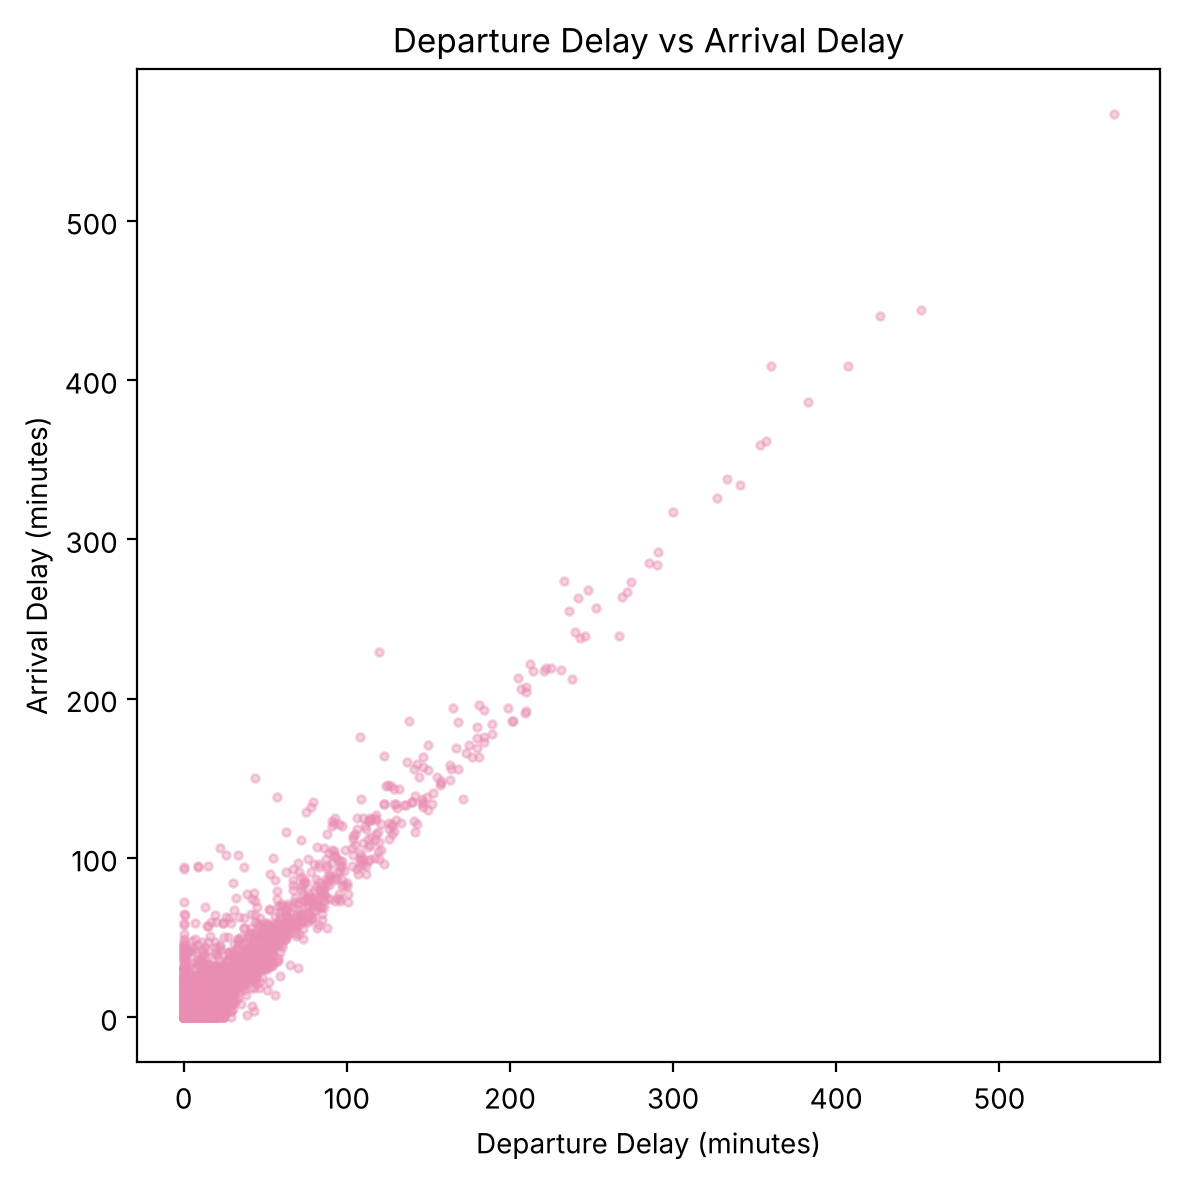

In [30]:
delay_sample = train_df.sample(n=5000, random_state=42)

plt.figure(figsize=(6, 6))

plt.scatter(
    delay_sample["Departure Delay in Minutes"],
    delay_sample["Arrival Delay in Minutes"],
    s=8,
    alpha=0.4,
    color="#E98DB3"
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")

plt.tight_layout()
plt.show()

**Interpretation.**

- The two delays are almost perfectly correlated: the arrival delay brings very little
  information that the departure delay does not already contain.
- Passengers with a missing arrival delay have a satisfaction rate close to the global
  rate, so the missing values do not seem to follow a particular pattern.

**Implication for preprocessing.** Two simple options can be compared on the validation
set: impute the 310 missing values with the training median, or drop
*Arrival Delay in Minutes* and keep only the departure delay.

## 18. Summary: EDA findings and preprocessing plan

| EDA finding | Planned action (to compare on the validation set) |
|---|---|
| `id` and `Unnamed: 0` are identifiers | Drop them |
| 310 missing arrival delays (0.30%), delays correlated at 0.965 | Median imputation (training median) **or** drop arrival delay |
| No duplicated rows | No removal needed |
| 4 categorical features | Binary encoding for 2-category features, one-hot encoding for *Class* |
| Different scales, long-tailed delays | Standardization fitted on the training set (needed for KNN and logistic regression, not for trees) |
| Moderate class imbalance (57% / 43%) | No resampling; report accuracy together with precision, recall and F1 |
| Zero ratings strongly related to satisfaction (Wi-Fi) | Keep zeros + add zero indicators, compared with keeping zeros only |
| Class and type of travel related; Simpson's paradox on schedule convenience | Interpret features with a trained model, not with averages alone |

The test set (`test.csv`) is not used to make any of these decisions.